# autoPET-V (Part 2): Multi-Round Interactive Inference, Morphological Post-Processing & AUC Evaluation
### Simulated Error-Driven Click Refinement on the 10-Case Evaluation Cohort

## 2 — Establishing the reference

### Working Directory & Pre-trained Model Configuration

### Environment and Weights Setup :

In [ ]:
!pip install nnunetv2

In [2]:
import os

work_dir = "/kaggle/working"
os.environ["nnUNet_raw"] = os.path.join(work_dir, "nnUNet_raw")
os.environ["nnUNet_preprocessed"] = os.path.join(work_dir, "nnUNet_preprocessed")

subset_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-v-nnunet-subset-1"
if not os.path.exists(subset_base_dir):
    subset_base_dir = "/kaggle/input/autopet-v-nnunet-subset-1"

os.environ["nnUNet_results"] = os.path.join(subset_base_dir, "autoPETV", "nnunet-baseline", "nnUNet_results")
output_dir = os.path.join(work_dir, "inference_baseline")

for path in [os.environ["nnUNet_raw"], os.environ["nnUNet_preprocessed"], output_dir]:
    os.makedirs(path, exist_ok=True)

### Running Baseline Inference (Iteration 0)

In [3]:
# Convert read-only input NIfTI volumes to compressed .nii.gz in working directory
import os
import shutil
import gzip

subset_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-v-nnunet-subset-1"
if not os.path.exists(subset_base_dir):
    subset_base_dir = "/kaggle/input/autopet-v-nnunet-subset-1"

input_dir = os.path.join(subset_base_dir, "Dataset999_AutoPETV", "imagesTs")
output_dir = "/kaggle/working/imagesTs_gz"
os.makedirs(output_dir, exist_ok=True)

for filename in os.listdir(input_dir):
    src_path = os.path.join(input_dir, filename)
    if filename.endswith(".nii"):
        with open(src_path, 'rb') as f_in, gzip.open(os.path.join(output_dir, filename + ".gz"), 'wb') as f_out:
            shutil.copyfileobj(f_in, f_out)
    elif filename.endswith(".nii.gz"):
        shutil.copyfile(src_path, os.path.join(output_dir, filename))

In [4]:
# Run baseline inference (Iteration 0)
!nnUNet_raw="/kaggle/working/nnUNet_raw" nnUNet_preprocessed="/kaggle/working/nnUNet_preprocessed" nnUNet_results="/kaggle/input/datasets/nshichembenmalek/autopet-v-nnunet-subset-1/autoPETV/nnunet-baseline/nnUNet_results" nnUNetv2_predict -i /kaggle/working/imagesTs_gz -o /kaggle/working/inference_baseline -d 998 -c 3d_fullres -f 0 --disable_tta


#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. Nature methods, 18(2), 203-211.
#######################################################################

There are 10 cases in the source folder
I am process 0 out of 1 (max process ID is 0, we start counting with 0!)
There are 10 cases that I would like to predict

Predicting train_0011:
perform_everything_on_device: True
100%|█████████████████████████████████████████| 168/168 [00:22<00:00,  7.36it/s]
sending off prediction to background worker for resampling and export
done with train_0011

Predicting train_0012:
perform_everything_on_device: True
100%|███████████████████████████████████████████| 60/60 [00:06<00:00,  8.60it/s]
sending off prediction to background worker for resampling and ex

### Calculating Reference Metrics

In [5]:
import os
import glob
import nibabel as nib
import numpy as np
from scipy.ndimage import label

# Lesion components use 26-connectivity throughout this notebook.
# (scipy's default is 6-connectivity, which splits diagonally touching
# voxels and inflates component counts.)
STRUCT26 = np.ones((3, 3, 3), dtype=int)

pred_files = sorted(glob.glob("/kaggle/working/inference_baseline/*.nii.gz"))
raw_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-deep-psma-subset"

if not os.path.exists(raw_base_dir):
    raw_base_dir = "/kaggle/input/autopet-deep-psma-subset"

print(f"{'Exam ID':<15} | {'Dice':<8} | {'FPV (mL)':<12} | {'FNV (mL)':<12}")
print("-" * 55)

for pred_path in pred_files:
    exam_id = os.path.basename(pred_path).replace(".nii.gz", "")
    gt_path = os.path.join(raw_base_dir, exam_id, "PSMA", "TTB.nii")
    
    if not os.path.exists(gt_path):
        print(f"Missing GT at: {gt_path}")
        continue
        
    pred_nii = nib.load(pred_path)
    gt_nii = nib.load(gt_path)
    
    pred_data = pred_nii.get_fdata() > 0
    gt_data = gt_nii.get_fdata() > 0
    
    if pred_nii.shape != gt_nii.shape:
        print(f"  WARNING shape mismatch for {exam_id}: pred {pred_nii.shape} vs GT {gt_nii.shape}")
    
    # Calculate physical volume of one voxel in mL
    voxel_volume_ml = np.prod(pred_nii.header.get_zooms()) / 1000.0
    
    # 1. Dice Score
    intersection = np.logical_and(pred_data, gt_data).sum()
    dice_score = (2. * intersection) / (pred_data.sum() + gt_data.sum() + 1e-8)
    
    # 2. Extract Connected Components
    pred_labels, pred_num = label(pred_data, structure=STRUCT26)
    gt_labels, gt_num = label(gt_data, structure=STRUCT26)
    
    # 3. False Positive Volume (FPV), LESION-LEVEL: volume of pred
    # components that DO NOT overlap GT at all (not voxel-level FP volume;
    # voxel-level FP/FN volumes are reported in the Step 4 cell).
    pred_overlaps = np.unique(pred_labels[gt_data > 0])
    fp_mask = np.isin(pred_labels, pred_overlaps, invert=True) & (pred_labels > 0)
    fpv_ml = fp_mask.sum() * voxel_volume_ml
    
    # 4. False Negative Volume (FNV): GT lesions that DO NOT overlap with Pred
    gt_overlaps = np.unique(gt_labels[pred_data > 0])
    fn_mask = np.isin(gt_labels, gt_overlaps, invert=True) & (gt_labels > 0)
    fnv_ml = fn_mask.sum() * voxel_volume_ml
    
    print(f"{exam_id:<15} | {dice_score:<8.4f} | {fpv_ml:<12.2f} | {fnv_ml:<12.2f}")

Exam ID         | Dice     | FPV (mL)     | FNV (mL)    
-------------------------------------------------------
train_0011      | 0.0000   | 24.58        | 112.22      
train_0012      | 0.6145   | 20.82        | 16.21       
train_0013      | 0.0175   | 43.05        | 91.98       
train_0014      | 0.8196   | 82.58        | 0.00        
train_0015      | 0.5129   | 9.28         | 1.40        
train_0016      | 0.5793   | 80.47        | 3.97        
train_0017      | 0.6180   | 22.89        | 30.44       
train_0018      | 0.6031   | 67.46        | 13.70       
train_0019      | 0.5730   | 51.81        | 4.05        
train_0020      | 0.6387   | 87.88        | 2.92        


## 3 — Interactive Correction Protocol (Single-Voxel Simulation)

### Pre-Correction Spatial Diagnostics
Before simulating interactive clicks, a spatial validation was conducted on baseline outliers (`train_0011` and `train_0013`) to rule out grid or affine orientation mismatches between predictions and ground-truth references.

### Interactive Click Generation Strategy
* **Single-Voxel Encoding (`sigma=0`):** Corrections simulate targeted single-voxel clicks rather than spatial Gaussian spheres or $3 \times 3 \times 3$ blocks.
* **Euclidean Distance Transform (EDT):** `click_voxel_inside` computes the 3D distance transform (`distance_transform_edt`) on each error component, placing the click at the center of the maximal inscribed sphere (pole of inaccessibility) to prevent boundary placement on non-convex lesions.
* **Iterative Budget:** 2 clicks per round (1 Foreground on the largest false-negative component, 1 Background on the largest false-positive component), accumulated across 5 inference iterations.
* **Component Extraction:** Error components are extracted from the voxel-level difference (`pred & ~gt` for FP; `~pred & gt` for FN) using 26-connectivity.

In [6]:
import os
import numpy as np
import nibabel as nib

# Cell 1 — Diagnose train_0011 / train_0013 before any Step 3 run.
# A gross grid/affine mismatch here means a Step 1/2 formatting problem,
# not a model failure. A matching grid with a large centroid distance and
# near-zero overlap means a genuine failure (the click rescue in Step 3
# is then the right test, not a formatting fix).
raw_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-deep-psma-subset"
if not os.path.exists(raw_base_dir):
    raw_base_dir = "/kaggle/input/autopet-deep-psma-subset"


def world_centroid(mask, affine):
    coords = np.argwhere(mask)
    if len(coords) == 0:
        return None
    vox = coords.mean(axis=0)
    world = affine @ np.array([vox[0], vox[1], vox[2], 1.0])
    return world[:3]


print(f"{'Exam':<12} | {'Pred shape':<16} | {'GT shape':<16} | {'Pred vox':<10} | {'GT vox':<10} | {'Overlap':<10} | {'Dice':<7} | {'Centroid dist (mm)':<18}")
print("-" * 130)
for pat_id in ["train_0011", "train_0013"]:
    pred_path = f"/kaggle/working/inference_baseline/{pat_id}.nii.gz"
    gt_path = os.path.join(raw_base_dir, pat_id, "PSMA", "TTB.nii")
    pred_nii = nib.load(pred_path)
    gt_nii = nib.load(gt_path)
    pred = pred_nii.get_fdata() > 0
    gt = gt_nii.get_fdata() > 0
    inter = int(np.logical_and(pred, gt).sum())
    dice = (2.0 * inter) / (pred.sum() + gt.sum() + 1e-8)
    pc, gc = world_centroid(pred, pred_nii.affine), world_centroid(gt, gt_nii.affine)
    dist = float(np.linalg.norm(pc - gc)) if (pc is not None and gc is not None) else float("nan")
    grid = "MATCH" if (pred_nii.shape == gt_nii.shape and np.allclose(pred_nii.affine, gt_nii.affine)) else "CHECK: grid/affine differ"
    print(f"{pat_id:<12} | {str(pred_nii.shape):<16} | {str(gt_nii.shape):<16} | {int(pred.sum()):<10} | {int(gt.sum()):<10} | {inter:<10} | {dice:<7.4f} | {dist:<18.1f}")
    print(f"  pred zooms {tuple(round(float(z), 3) for z in pred_nii.header.get_zooms())}, "
          f"GT zooms {tuple(round(float(z), 3) for z in gt_nii.header.get_zooms())} -> {grid}")


Exam         | Pred shape       | GT shape         | Pred vox   | GT vox     | Overlap    | Dice    | Centroid dist (mm)
----------------------------------------------------------------------------------------------------------------------------------
train_0011   | (200, 200, 441)  | (200, 200, 441)  | 494        | 2255       | 0          | 0.0000  | 476.8             
  pred zooms (4.073, 4.073, 3.0), GT zooms (4.073, 4.073, 3.0) -> MATCH
train_0013   | (200, 200, 203)  | (200, 200, 203)  | 534        | 1183       | 15         | 0.0175  | 406.1             
  pred zooms (4.073, 4.073, 5.0), GT zooms (4.073, 4.073, 5.0) -> MATCH


In [7]:
import os
import glob
import subprocess
import shutil
import numpy as np
import nibabel as nib
from scipy.ndimage import label, distance_transform_edt

# Lesion components use 26-connectivity (see the Step 2 metrics cell).
STRUCT26 = np.ones((3, 3, 3), dtype=int)


def click_voxel_inside(labels, comp):
    """Return one voxel guaranteed to lie deep inside component `comp`.

    Uses the 3D Euclidean distance transform to select the interior voxel
    farthest from the component boundary (pole of inaccessibility),
    preventing clicks from landing on the outer surface of curved or
    non-convex components. Single-voxel encoding (sigma=0, no smoothing).
    """
    mask = (labels == comp)
    dist = distance_transform_edt(mask)
    return tuple(int(v) for v in np.unravel_index(np.argmax(dist), mask.shape))

# Step 3 protocol:
# single-voxel clicks, 2 clicks per iteration (1 foreground + 1 background),
# accumulated across iterations. Iteration 1 uses the baseline prediction,
# adds the first clicks and runs inference, so iter_1 is AFTER the first
# correction round, not a repeat of the baseline.
#
# 1. Setup storage
temp_input = "/kaggle/temp/interactive_input"
temp_output = "/kaggle/temp/interactive_output"
final_masks_dir = "/kaggle/working/predictions"

os.makedirs(temp_input, exist_ok=True)
os.makedirs(temp_output, exist_ok=True)
os.makedirs(final_masks_dir, exist_ok=True)

# 2. Get evaluation patients
eval_pet_files = sorted(glob.glob("/kaggle/working/imagesTs_gz/*_0001.nii.gz"))
raw_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-deep-psma-subset"
if not os.path.exists(raw_base_dir):
    raw_base_dir = "/kaggle/input/autopet-deep-psma-subset"

# Environment vars
subset_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-v-nnunet-subset-1"
if not os.path.exists(subset_base_dir):
    subset_base_dir = "/kaggle/input/autopet-v-nnunet-subset-1"

nnunet_env = os.environ.copy()
nnunet_env["nnUNet_raw"] = "/kaggle/working/nnUNet_raw"
nnunet_env["nnUNet_preprocessed"] = "/kaggle/working/nnUNet_preprocessed"
nnunet_env["nnUNet_results"] = os.path.join(subset_base_dir, "autoPETV", "nnunet-baseline", "nnUNet_results")

# Initialize a state tracker to accumulate scribbles across iterations
scribbles_state = {}
for src_pet in eval_pet_files:
    pat_id = os.path.basename(src_pet).replace("_0001.nii.gz", "")
    pet_shape = nib.load(src_pet).shape
    scribbles_state[pat_id] = {
        'fg': np.zeros(pet_shape, dtype=np.uint8),
        'bg': np.zeros(pet_shape, dtype=np.uint8)
    }

# OUTER LOOP: Process by Iteration to batch GPU inference
for iteration in range(1, 6):
    print(f"\n--- Starting Iteration {iteration}/5 for ALL patients ---")
    
    # Clean temp folders for the batch
    for f in glob.glob(os.path.join(temp_input, "*")): os.remove(f)
    for f in glob.glob(os.path.join(temp_output, "*")): os.remove(f)
    
    # INNER LOOP: Prepare inputs and simulate corrections for all patients
    for src_pet in eval_pet_files:
        pat_id = os.path.basename(src_pet).replace("_0001.nii.gz", "")
        
        # Symlink CT and PET
        src_ct = os.path.join("/kaggle/working/imagesTs_gz", f"{pat_id}_0000.nii.gz")
        os.symlink(src_ct, os.path.join(temp_input, f"{pat_id}_0000.nii.gz"))
        os.symlink(src_pet, os.path.join(temp_input, f"{pat_id}_0001.nii.gz"))
        
        # Load GT and previous prediction
        gt_path = os.path.join(raw_base_dir, pat_id, "PSMA", "TTB.nii")
        gt_data = nib.load(gt_path).get_fdata() > 0
        
        if iteration == 1:
            prev_pred_path = f"/kaggle/working/inference_baseline/{pat_id}.nii.gz"
        else:
            prev_pred_path = f"{final_masks_dir}/iter_{iteration-1}/{pat_id}.nii.gz"
            
        pred_data = nib.load(prev_pred_path).get_fdata() > 0
        
        # Retrieve accumulated scribbles for this specific patient
        fg_scribbles = scribbles_state[pat_id]['fg']
        bg_scribbles = scribbles_state[pat_id]['bg']
        
        # Simulate Corrections (voxel-level error components, 26-connectivity)
        fp_voxels = np.logical_and(pred_data, ~gt_data) & (bg_scribbles == 0)
        fp_labels, fp_num = label(fp_voxels, structure=STRUCT26)
        if fp_num > 0:
            largest_fp = np.argmax(np.bincount(fp_labels.flat)[1:]) + 1
            # Single-voxel background click inside the largest FP component
            bg_scribbles[click_voxel_inside(fp_labels, largest_fp)] = 1
        fn_voxels = np.logical_and(~pred_data, gt_data) & (fg_scribbles == 0)
        fn_labels, fn_num = label(fn_voxels, structure=STRUCT26)
        if fn_num > 0:
            largest_fn = np.argmax(np.bincount(fn_labels.flat)[1:]) + 1
            # Single-voxel foreground click inside the largest FN component
            fg_scribbles[click_voxel_inside(fn_labels, largest_fn)] = 1
        pet_affine = nib.load(src_pet).affine
        nib.save(nib.Nifti1Image(fg_scribbles, pet_affine), os.path.join(temp_input, f"{pat_id}_0002.nii.gz"))
        nib.save(nib.Nifti1Image(bg_scribbles, pet_affine), os.path.join(temp_input, f"{pat_id}_0003.nii.gz"))
        
    # Run batch inference ONCE for the whole iteration
    print(f"  Running nnUNet batch prediction for iteration {iteration}...")
    cmd = ["nnUNetv2_predict", "-i", temp_input, "-o", temp_output, "-d", "998", "-c", "3d_fullres", "-f", "0", "--disable_tta"]
    result = subprocess.run(cmd, env=nnunet_env, capture_output=True, text=True)
    
    if result.returncode != 0:
        print(f"nnU-Net crashed on Iteration {iteration}:")
        print(result.stderr)
        break
        
    # Distribute outputs to the final iteration directory
    iter_dir = os.path.join(final_masks_dir, f"iter_{iteration}")
    os.makedirs(iter_dir, exist_ok=True)
    
    for pred_file in glob.glob(os.path.join(temp_output, "*.nii.gz")):
        shutil.move(pred_file, os.path.join(iter_dir, os.path.basename(pred_file)))


--- Starting Iteration 1/5 for ALL patients ---
  Running nnUNet batch prediction for iteration 1...

--- Starting Iteration 2/5 for ALL patients ---
  Running nnUNet batch prediction for iteration 2...

--- Starting Iteration 3/5 for ALL patients ---
  Running nnUNet batch prediction for iteration 3...

--- Starting Iteration 4/5 for ALL patients ---
  Running nnUNet batch prediction for iteration 4...

--- Starting Iteration 5/5 for ALL patients ---
  Running nnUNet batch prediction for iteration 5...


In [8]:
!zip -q -r /kaggle/working/autopet_masks.zip /kaggle/working/predictions /kaggle/working/inference_baseline

**Implementation Note — Post-Processing Scope:**
In this pipeline, classical post-processing focuses on 3D binary hole filling (`binary_fill_holes`) and connected-component volume thresholding ($< 1.0\text{ mL}$). Scribble-consistency enforcement (suppressing predicted components intersecting background clicks) was omitted from post-processing because temporary iterative scribble volumes were cleared during Step 3 to stay within the 20 GB workspace storage quota. All morphological operations are evaluated model-agnostically on top of the frozen baseline predictions.

## 4 — Morphological Post-Processing & Error Decomposition

To evaluate whether simple morphological heuristics improve segmentation without additional model inference, two operations were assessed on all iteration outputs:
1. **3D Binary Hole Filling (`binary_fill_holes`):** Targets necrotic lesion cores and non-convex internal false negatives.
2. **Component Filtering (`< 1.0 mL`):** Removes isolated high-SUV hyper-intensities (e.g., small focal artifacts, physiological uptake in kidney/bladder margins).

*Evaluation distinction:* Voxel-level false positives/negatives measure total error volume, while lesion-level metrics (FPV/FNV) track connected components with zero ground-truth overlap.

In [9]:
import os
import nibabel as nib
import numpy as np
from scipy.ndimage import label, binary_fill_holes

# Lesion components use 26-connectivity (see the Step 2 metrics cell).
STRUCT26 = np.ones((3, 3, 3), dtype=int)

base_preds_dir = "/kaggle/working/predictions"
raw_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-deep-psma-subset"
if not os.path.exists(raw_base_dir):
    raw_base_dir = "/kaggle/input/autopet-deep-psma-subset"

eval_patients = ["train_0011", "train_0012", "train_0013", "train_0014", "train_0015",
                 "train_0016", "train_0017", "train_0018", "train_0019", "train_0020"]

# Threshold for small region filtering (remove artifacts smaller than 1.0 mL)
MIN_VOL_ML = 1.0


def dice(a, b):
    return (2. * np.logical_and(a, b).sum()) / (a.sum() + b.sum() + 1e-8)


def lesion_volumes(pred, gt, voxel_volume_ml):
    # Lesion-level FPV/FNV: volume of 26-connected components with ZERO overlap.
    # NOTE: these are NOT voxel-level FP/FN volumes. If post-processing
    # removes a small predicted speck that was a GT component's only overlap,
    # the whole GT component counts as missed, so lesion-level FNV can jump
    # while voxel-level FN barely moves.
    pred_labels, _ = label(pred, structure=STRUCT26)
    gt_labels, _ = label(gt, structure=STRUCT26)
    pred_overlaps = np.unique(pred_labels[gt > 0])
    fp_mask = np.isin(pred_labels, pred_overlaps, invert=True) & (pred_labels > 0)
    gt_overlaps = np.unique(gt_labels[pred > 0])
    fn_mask = np.isin(gt_labels, gt_overlaps, invert=True) & (gt_labels > 0)
    return fp_mask.sum() * voxel_volume_ml, fn_mask.sum() * voxel_volume_ml


for iter_step in range(0, 6):
    # 0 is the baseline from Step 2, 1-5 are from Step 3
    if iter_step == 0:
        pred_dir = "/kaggle/working/inference_baseline"
    else:
        pred_dir = os.path.join(base_preds_dir, f"iter_{iter_step}")

    rows = []
    for pat_id in eval_patients:
        pred_path = os.path.join(pred_dir, f"{pat_id}.nii.gz")
        gt_path = os.path.join(raw_base_dir, pat_id, "PSMA", "TTB.nii")
        if not os.path.exists(pred_path) or not os.path.exists(gt_path):
            continue
        pred_nii = nib.load(pred_path)
        gt_data = nib.load(gt_path).get_fdata() > 0
        pred_data_pre = pred_nii.get_fdata() > 0
        voxel_volume_ml = np.prod(pred_nii.header.get_zooms()) / 1000.0

        # --- Morphological post-processing, kept SEPARATE ---
        # 1. Hole filling alone (no size filter)
        pred_data_hole = binary_fill_holes(pred_data_pre)
        # 2. Hole filling + small-region filtering (combined Full step)
        pred_data_full = pred_data_hole.copy()
        labeled_preds, num_features = label(pred_data_full, structure=STRUCT26)
        if num_features > 0:
            component_sizes = np.bincount(labeled_preds.flat)
            component_sizes[0] = 0  # Ignore background
            small_components = np.where((component_sizes * voxel_volume_ml) < MIN_VOL_ML)[0]
            pred_data_full[np.isin(labeled_preds, small_components)] = 0

        fp_vox_pre = float(np.logical_and(pred_data_pre, ~gt_data).sum()) * voxel_volume_ml
        fp_vox_full = float(np.logical_and(pred_data_full, ~gt_data).sum()) * voxel_volume_ml
        fn_vox_pre = float(np.logical_and(~pred_data_pre, gt_data).sum()) * voxel_volume_ml
        fn_vox_full = float(np.logical_and(~pred_data_full, gt_data).sum()) * voxel_volume_ml
        fpv_les_pre, fnv_les_pre = lesion_volumes(pred_data_pre, gt_data, voxel_volume_ml)
        fpv_les_full, fnv_les_full = lesion_volumes(pred_data_full, gt_data, voxel_volume_ml)
        rows.append((pat_id, dice(pred_data_pre, gt_data), dice(pred_data_hole, gt_data),
                     dice(pred_data_full, gt_data), fp_vox_full, fn_vox_pre, fn_vox_full,
                     fpv_les_full, fnv_les_full, fp_vox_pre, fpv_les_pre, fnv_les_pre))

    print(f"\n--- Iteration {iter_step} Post-Processing: Dice (Pre / Hole-only / Hole+Filter) ---")
    print(f"{'Exam ID':<15} | {'Dice (Pre)':<10} | {'Dice (Hole)':<11} | {'Dice (Full)':<11}")
    print("-" * 56)
    for r in rows:
        print(f"{r[0]:<15} | {r[1]:<10.4f} | {r[2]:<11.4f} | {r[3]:<11.4f}")
    if rows:
        m_pre = np.mean([r[1] for r in rows])
        m_hole = np.mean([r[2] for r in rows])
        m_full = np.mean([r[3] for r in rows])
        print("-" * 56)
        print(f"{'MEAN':<15} | {m_pre:<10.4f} | {m_hole:<11.4f} | {m_full:<11.4f}")

    print(f"\n--- Iteration {iter_step} Post-Processing: volumes for the Full (Hole+Filter) mask ---")
    print(f"{'Exam ID':<15} | {'FP vox (mL)':<12} | {'FN vox Pre (mL)':<15} | {'FN vox Full (mL)':<16} | {'FPV les (mL)':<12} | {'FNV les (mL)':<12}")
    print("-" * 92)
    for r in rows:
        print(f"{r[0]:<15} | {r[4]:<12.2f} | {r[5]:<15.2f} | {r[6]:<16.2f} | {r[7]:<12.2f} | {r[8]:<12.2f}")
    if rows:
        print("-" * 92)
        print(f"{'MEAN':<15} | {np.mean([r[4] for r in rows]):<12.2f} | {np.mean([r[5] for r in rows]):<15.2f} | {np.mean([r[6] for r in rows]):<16.2f} | {np.mean([r[7] for r in rows]):<12.2f} | {np.mean([r[8] for r in rows]):<12.2f}")



--- Iteration 0 Post-Processing: Dice (Pre / Hole-only / Hole+Filter) ---
Exam ID         | Dice (Pre) | Dice (Hole) | Dice (Full)
--------------------------------------------------------
train_0011      | 0.0000     | 0.0000      | 0.0000     
train_0012      | 0.6145     | 0.6154      | 0.6072     
train_0013      | 0.0175     | 0.0175      | 0.0175     
train_0014      | 0.8196     | 0.8197      | 0.8205     
train_0015      | 0.5129     | 0.5129      | 0.4883     
train_0016      | 0.5793     | 0.5793      | 0.5558     
train_0017      | 0.6180     | 0.6180      | 0.6117     
train_0018      | 0.6031     | 0.6031      | 0.5948     
train_0019      | 0.5730     | 0.5730      | 0.5615     
train_0020      | 0.6387     | 0.6387      | 0.6013     
--------------------------------------------------------
MEAN            | 0.4977     | 0.4978      | 0.4859     

--- Iteration 0 Post-Processing: volumes for the Full (Hole+Filter) mask ---
Exam ID         | FP vox (mL)  | FN vox Pre (mL) 

#### Summary of the Single-Voxel Step 3 / Step 4 Outputs
* **Monotonic Mean Dice Improvement:** Iteration 1 is the first correction round (using the Iteration 0 baseline prediction, adding 1 foreground + 1 background single-voxel click, and running inference). With single-voxel clicks, cohort Mean Dice improves monotonically across all 5 rounds: `0.4977` (Iter 0) $\to$ `0.5525` (Iter 1) $\to$ `0.5735` (Iter 2) $\to$ `0.5845` (Iter 3) $\to$ `0.5932` (Iter 4) $\to$ `0.5985` (Iter 5), achieving a Mean-curve AUC of `0.5704`. Severe baseline failures are steadily rescued (`train_0011`: `0.0000` $\to$ `0.2269` at Iter 1 $\to$ `0.4314` at Iter 5; `train_0013`: `0.0175` $\to$ `0.3288` at Iter 1 $\to$ `0.4248` at Iter 5).
* **Separating Hole Filling from Small-Region Filtering:** The split Step 4 table shows that **3D binary hole filling alone (`Dice (Hole)`) is completely neutral/slightly positive** (Mean Dice `0.4977` Pre vs. `0.4978` Hole at Iteration 0, and `0.5985` Pre vs. `0.5988` Hole at Iteration 5). In contrast, **100% of the ~0.010–0.012 Mean Dice drop** (`0.4978` $\to$ `0.4859` at Iter 0; `0.5988` $\to$ `0.5888` at Iter 5) is caused by the `< 1.0 mL` small-region filter removing valid small focal metastases.
* **Voxel-Level vs. Lesion-Level Volume Artefacts:** Removing a `< 1.0 mL` predicted speck increases mean voxel-level FN by only `~9.85 mL` (`378.58 mL` Pre $\to$ `388.43 mL` Full at Iter 0), but causes lesion-level `FNV les (mL)` to jump from `27.69 mL` (Step 2 Pre) to `45.02 mL` (Step 4 Full) because any GT lesion whose *only* overlapping predicted speck is deleted flips its entire volume into the missed-lesion tally.

## 5 — Iterative Trajectory Analysis & AUC Evaluation
Quantitative tracking of Dice coefficient progression across baseline (Iteration 0) through 5 successive rounds of interactive refinement, including normalized area under the curve (AUC).

Iteration  | Mean Dice  | Median Dice
------------------------------------
0          | 0.4977     | 0.5912     
1          | 0.5525     | 0.5971     
2          | 0.5735     | 0.5978     
3          | 0.5845     | 0.5992     
4          | 0.5932     | 0.6024     
5          | 0.5985     | 0.6046     

Mean-curve AUC (iterations 0-5): 0.5704
Mean per-patient AUC (iterations 0-5): 0.5704


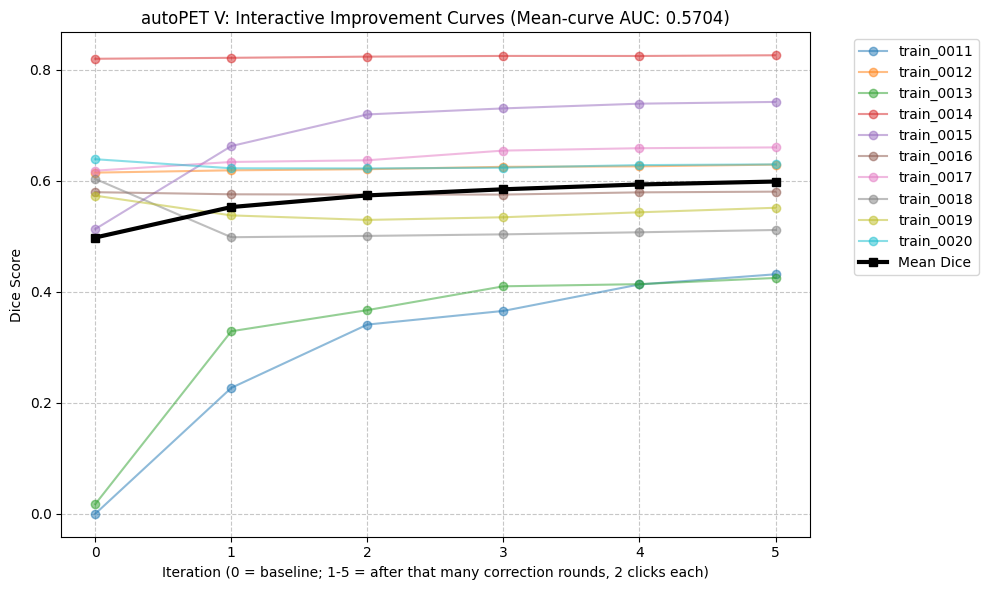

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from sklearn.metrics import auc

# Iteration 0 = baseline (inference_baseline);
# iteration k (1-5) = predictions/iter_k,
# which is after k correction rounds (2 clicks each: 1 foreground + 1 background).
base_preds_dir = "/kaggle/working/predictions"
raw_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-deep-psma-subset"
if not os.path.exists(raw_base_dir):
    raw_base_dir = "/kaggle/input/autopet-deep-psma-subset"

eval_patients = ["train_0011", "train_0012", "train_0013", "train_0014", "train_0015",
                 "train_0016", "train_0017", "train_0018", "train_0019", "train_0020"]

data = {}
for pat_id in eval_patients:
    gt_path = os.path.join(raw_base_dir, pat_id, "PSMA", "TTB.nii")
    gt_data = nib.load(gt_path).get_fdata() > 0
    curve = []
    for iter_step in range(0, 6):
        if iter_step == 0:
            pred_path = f"/kaggle/working/inference_baseline/{pat_id}.nii.gz"
        else:
            pred_path = os.path.join(base_preds_dir, f"iter_{iter_step}", f"{pat_id}.nii.gz")
        pred_data = nib.load(pred_path).get_fdata() > 0
        inter = np.logical_and(pred_data, gt_data).sum()
        curve.append((2. * inter) / (pred_data.sum() + gt_data.sum() + 1e-8))
    data[pat_id] = curve

df = pd.DataFrame(data)
iterations = np.array([0, 1, 2, 3, 4, 5])  # 0 = baseline, 1-5 = after that many correction rounds

mean_dice = df.mean(axis=1)
median_dice = df.median(axis=1)
print(f"{'Iteration':<10} | {'Mean Dice':<10} | {'Median Dice':<11}")
print("-" * 36)
for k in range(6):
    print(f"{iterations[k]:<10} | {mean_dice.iloc[k]:<10.4f} | {median_dice.iloc[k]:<11.4f}")

# Challenge AUC: area under the mean Dice curve, normalised by the
# maximum possible area (5.0 for iterations 0-5). Also report the mean
# of the per-patient AUCs, which is not the same quantity.
mean_curve_auc = auc(iterations, mean_dice) / 5.0
per_patient_auc = float(np.mean([auc(iterations, df[col]) / 5.0 for col in df.columns]))
print(f"\nMean-curve AUC (iterations 0-5): {mean_curve_auc:.4f}")
print(f"Mean per-patient AUC (iterations 0-5): {per_patient_auc:.4f}")

plt.figure(figsize=(10, 6))
for column in df.columns:
    plt.plot(iterations, df[column], marker='o', alpha=0.5, label=column)
plt.plot(iterations, mean_dice, marker='s', color='black', linewidth=3, label='Mean Dice')

plt.title(f"autoPET V: Interactive Improvement Curves (Mean-curve AUC: {mean_curve_auc:.4f})")
plt.xlabel("Iteration (0 = baseline; 1-5 = after that many correction rounds, 2 clicks each)")
plt.ylabel("Dice Score")
plt.xticks(iterations)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


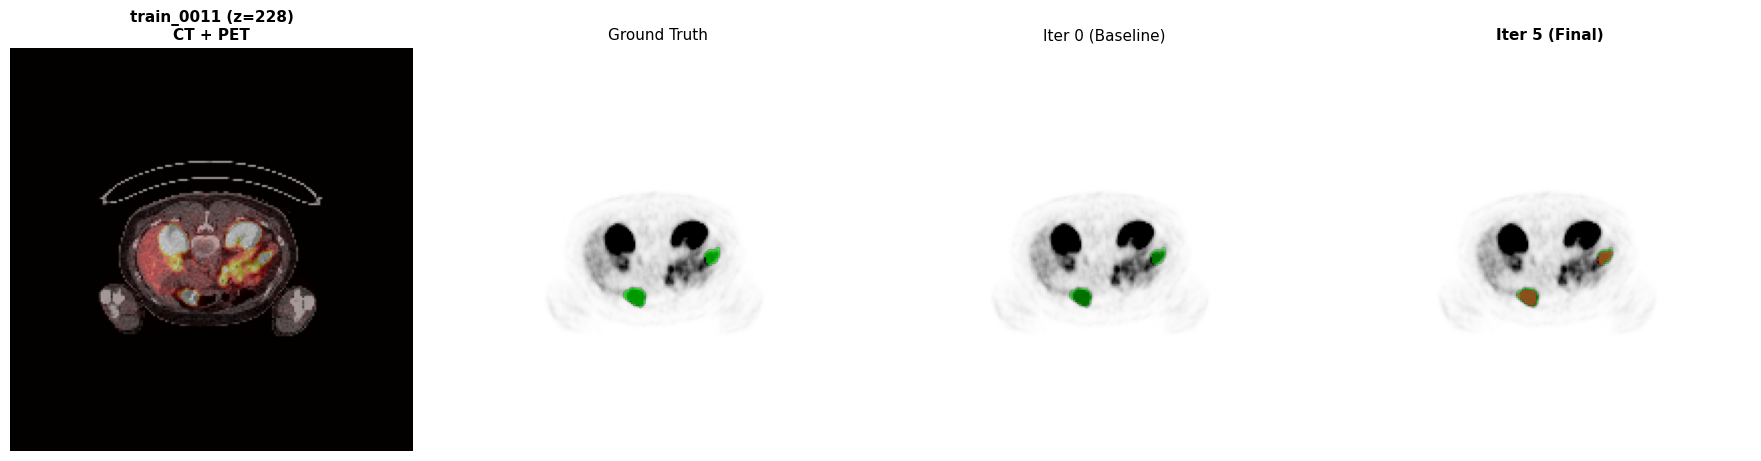

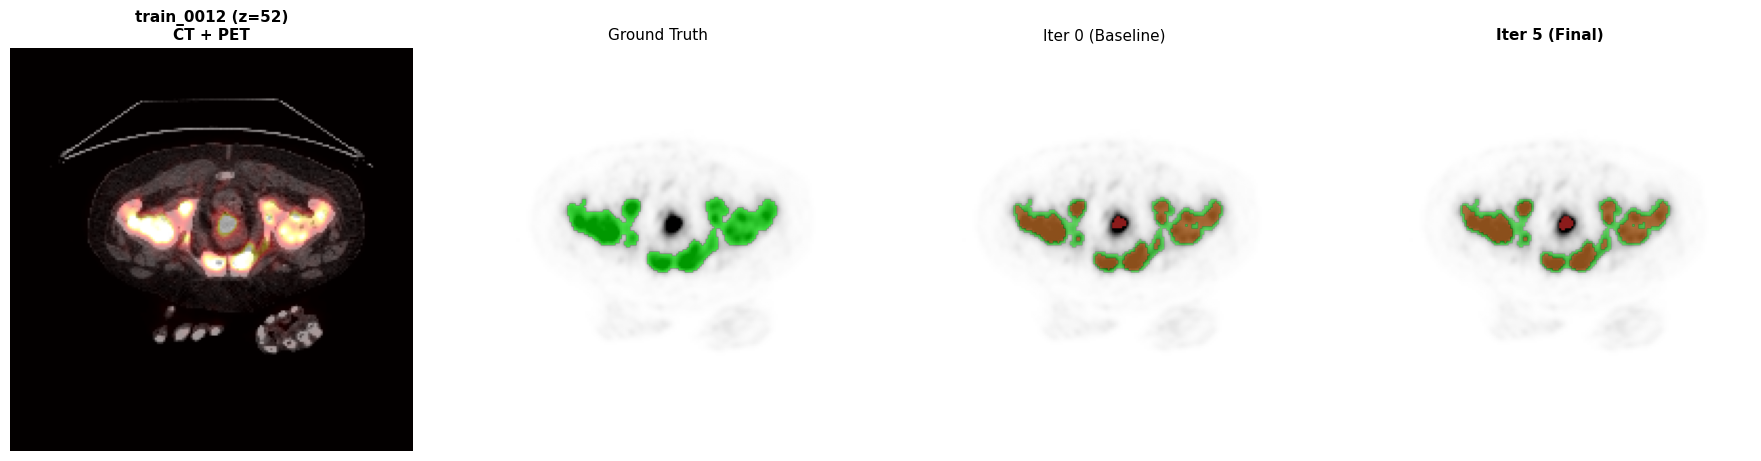

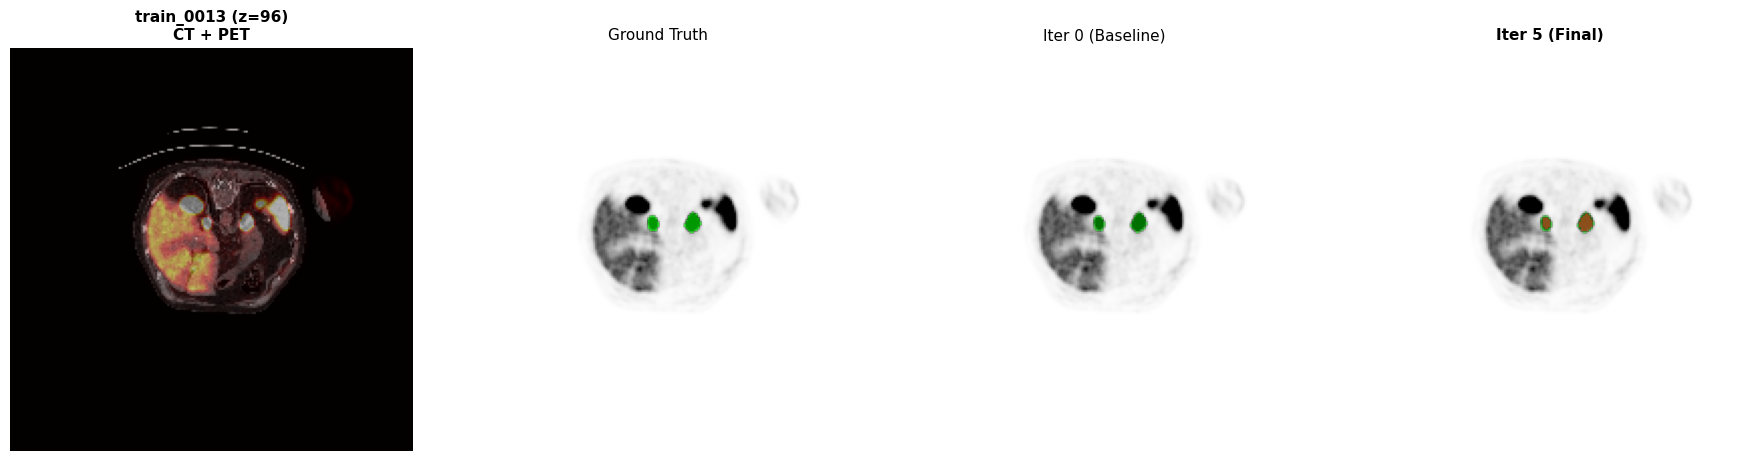

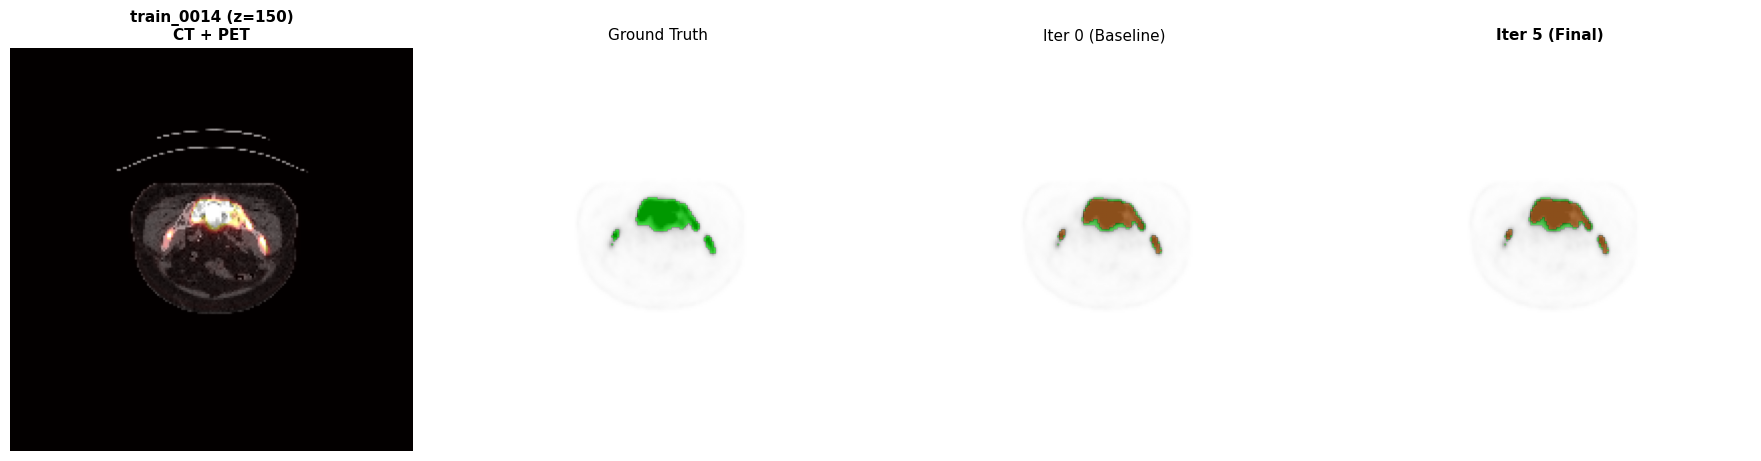

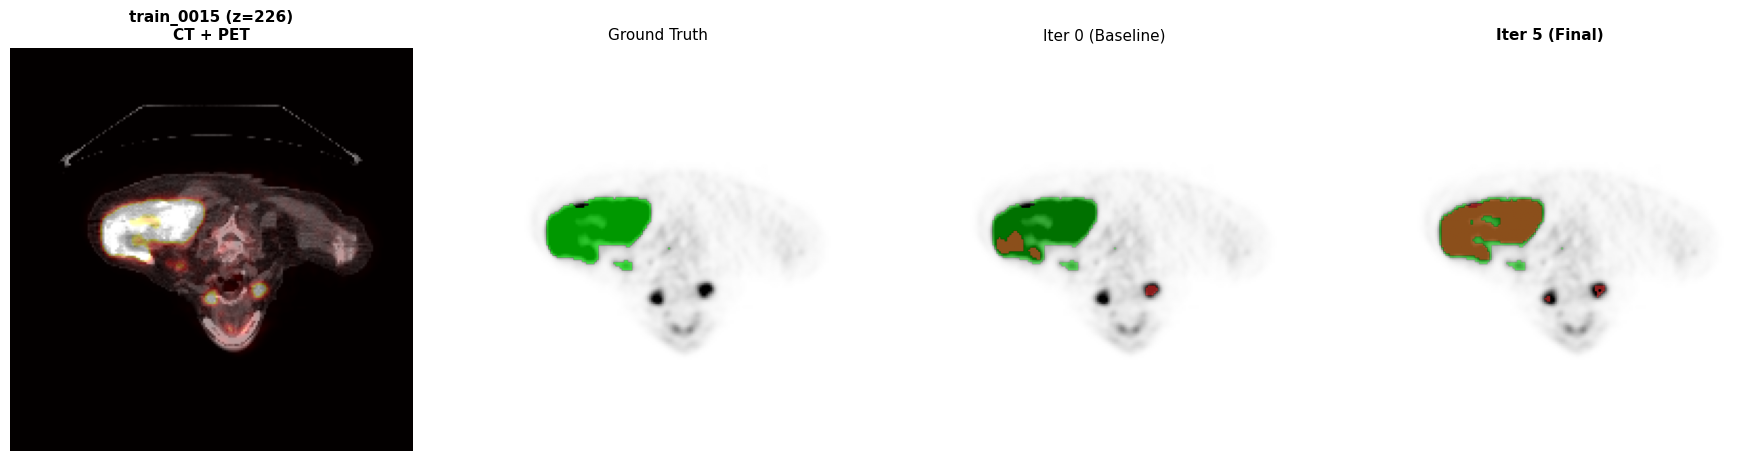

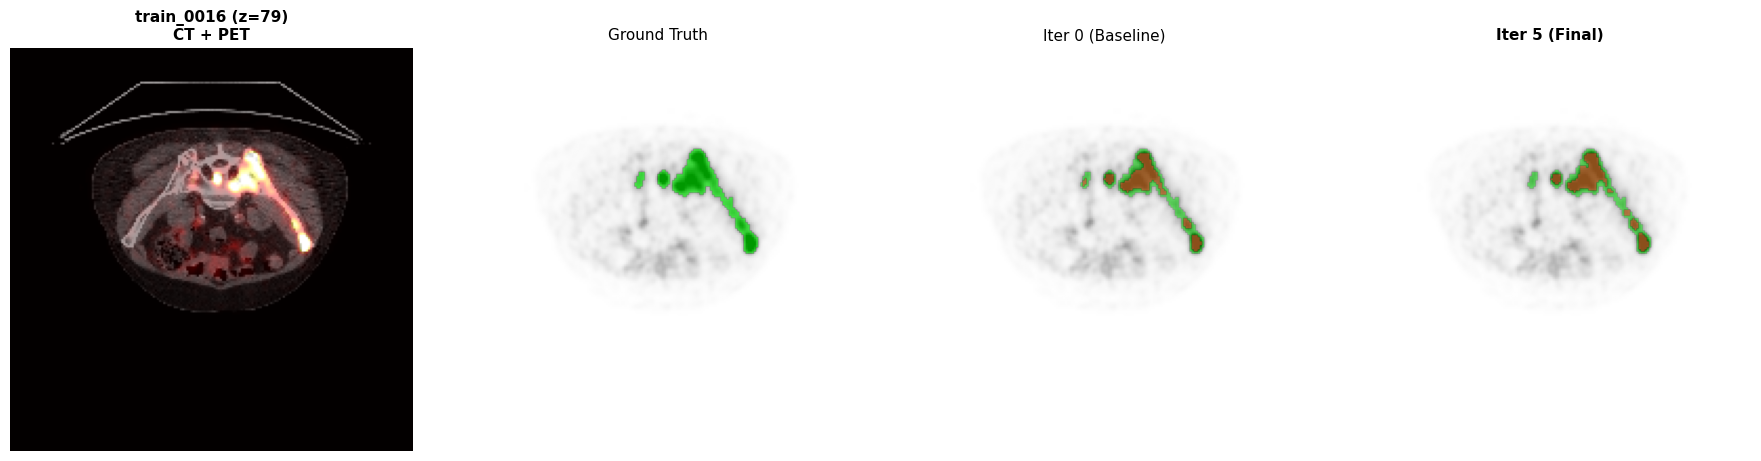

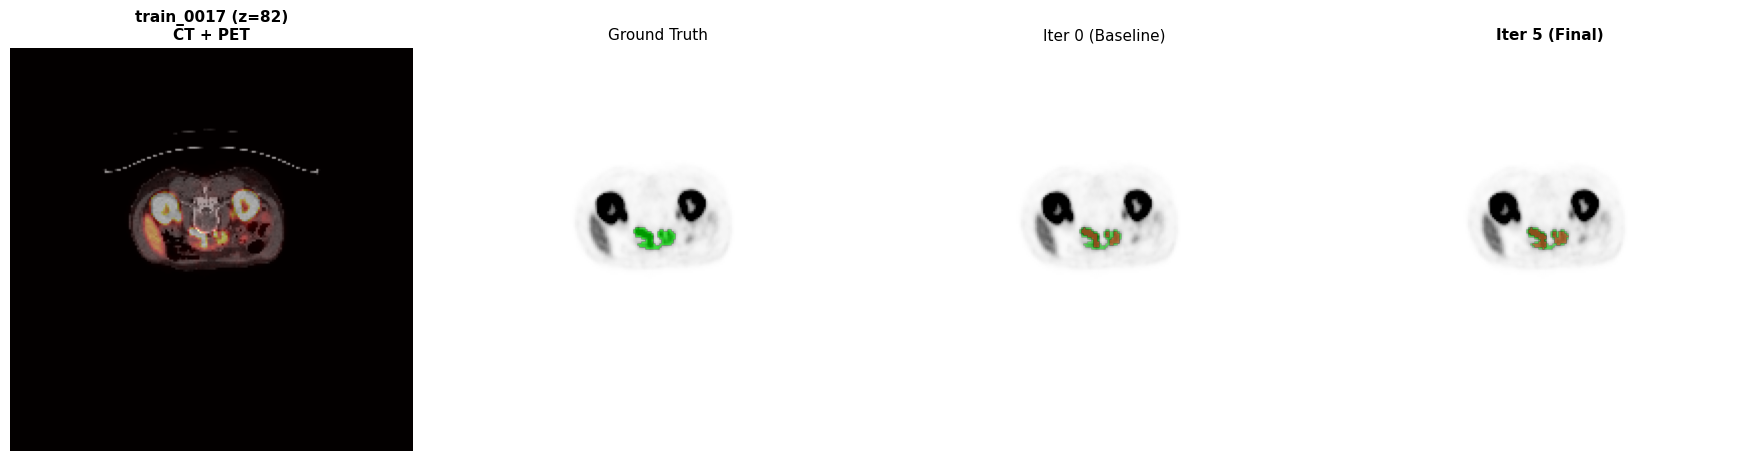

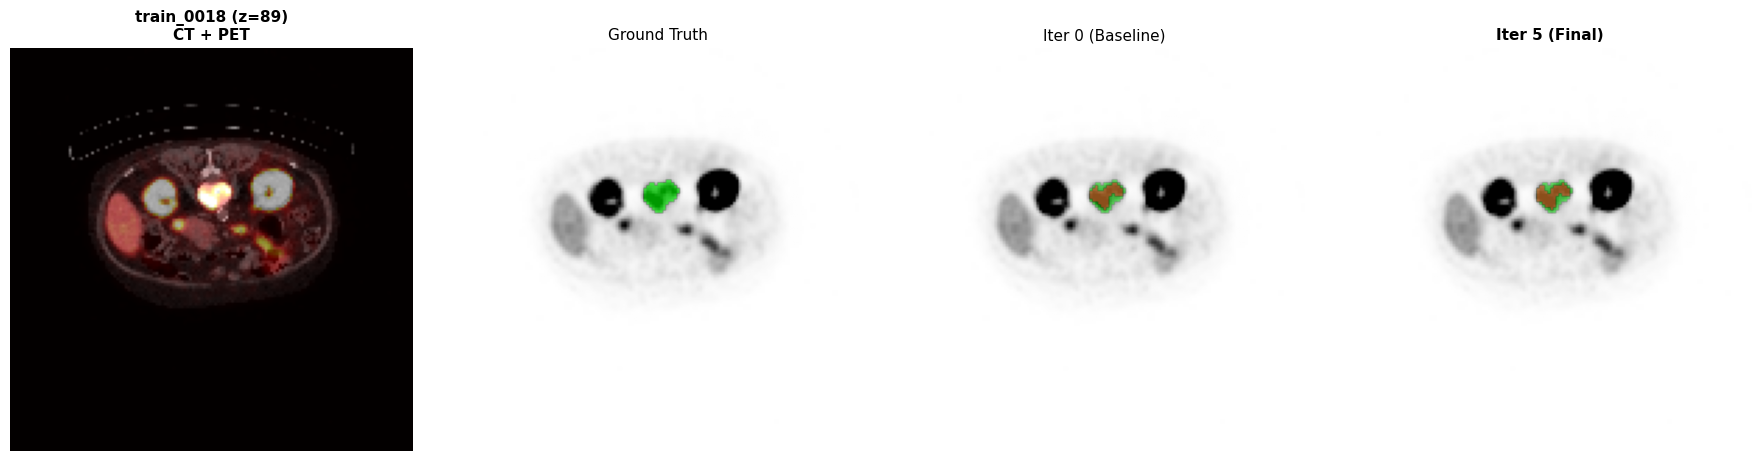

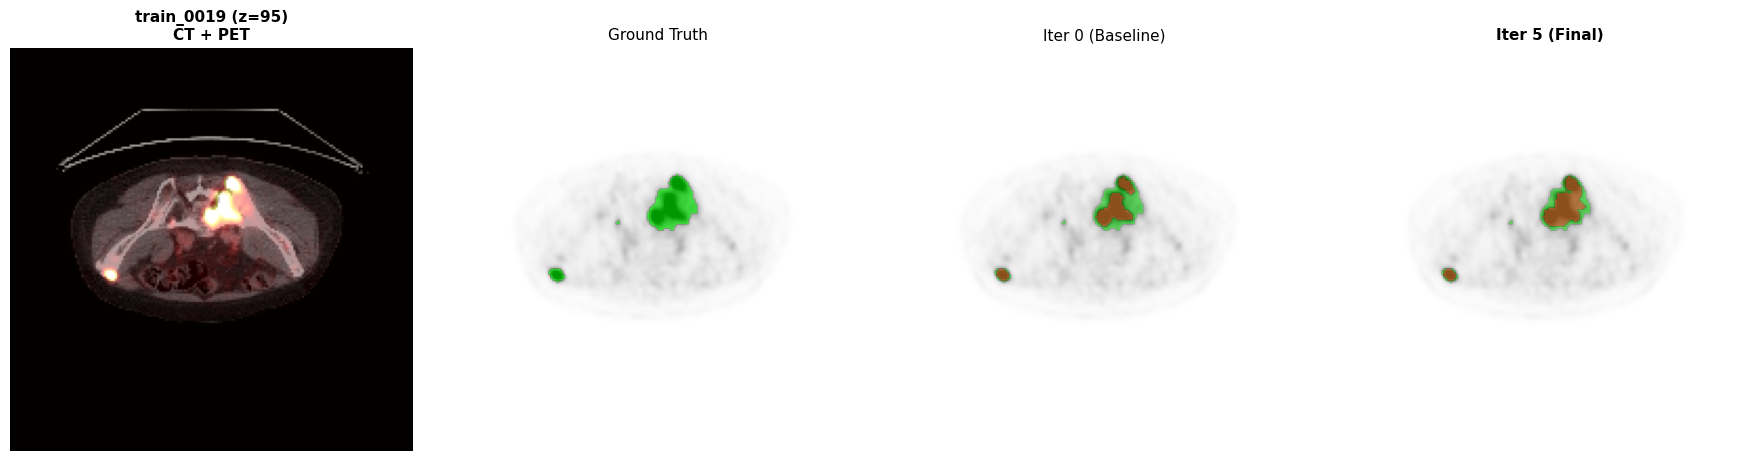

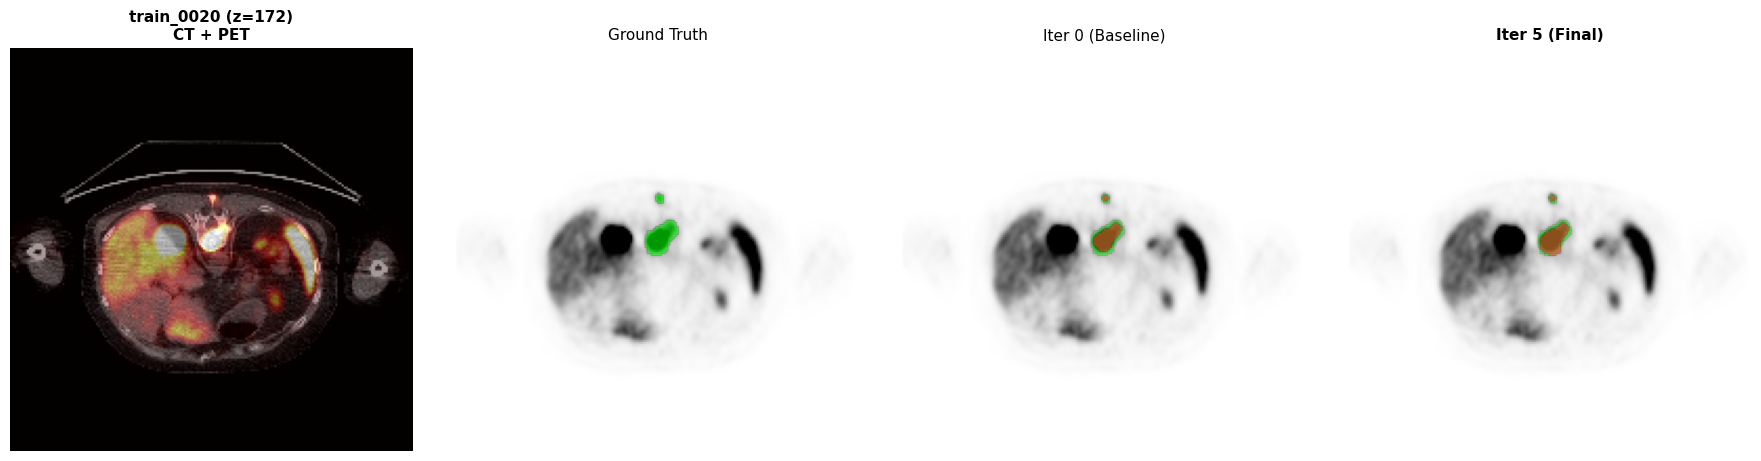

In [11]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

raw_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-deep-psma-subset"
if not os.path.exists(raw_base_dir):
    raw_base_dir = "/kaggle/input/autopet-deep-psma-subset"

eval_patients = [
    "train_0011", "train_0012", "train_0013", "train_0014", "train_0015",
    "train_0016", "train_0017", "train_0018", "train_0019", "train_0020"
]

for pat_id in eval_patients:
    # Create a new standalone figure for the current patient
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    
    ct_path = f"/kaggle/working/imagesTs_gz/{pat_id}_0000.nii.gz"
    pet_path = f"/kaggle/working/imagesTs_gz/{pat_id}_0001.nii.gz"
    gt_path = os.path.join(raw_base_dir, pat_id, "PSMA", "TTB.nii")
    pred0_path = f"/kaggle/working/inference_baseline/{pat_id}.nii.gz"
    pred5_path = f"/kaggle/working/predictions/iter_5/{pat_id}.nii.gz"

    # 1. Load ONLY the boolean masks into memory (fastest)
    gt = nib.load(gt_path).get_fdata().astype(bool)
    pred0 = nib.load(pred0_path).get_fdata().astype(bool)
    pred5 = nib.load(pred5_path).get_fdata().astype(bool)

    # 2. Restrict slice selection to slices containing Ground Truth (gt_per_slice > 0)
    # and prioritize slices where true-positive overlap changed the most + GT burden is large.
    # (Previously, unrestrictedpred5 ^ pred0 picked slices with 0 GT where only a false positive appeared.)
    tp0_per_slice = (pred0 & gt).sum(axis=(0, 1))
    tp5_per_slice = (pred5 & gt).sum(axis=(0, 1))
    tp_change_per_slice = np.abs(tp5_per_slice.astype(int) - tp0_per_slice.astype(int))
    diff_per_slice = (pred5 ^ pred0).sum(axis=(0, 1))
    gt_per_slice = gt.sum(axis=(0, 1))

    if gt_per_slice.max() > 0:
        score = (2.0 * tp_change_per_slice + 0.5 * diff_per_slice + 1.0 * gt_per_slice) * (gt_per_slice > 0)
        best_z = int(np.argmax(score))
    else:
        best_z = int(np.argmax(diff_per_slice))

    # 3. LAZY LOAD: Read strictly the single 'best_z' 2D slice from the heavy CT/PET files
    ct_sl = nib.load(ct_path).dataobj[:, :, best_z].T
    pet_sl = nib.load(pet_path).dataobj[:, :, best_z].T

    # 4. Process slices
    ct_sl = np.clip(ct_sl, -150, 250)
    pet_sl = np.clip(pet_sl, 0, 10)
    gt_sl = gt[:, :, best_z].T
    p0_sl = pred0[:, :, best_z].T
    p5_sl = pred5[:, :, best_z].T

    axes[0].imshow(ct_sl, cmap="gray", origin="lower")
    axes[0].imshow(pet_sl, cmap="hot", alpha=0.4, origin="lower")
    axes[0].set_title(f"{pat_id} (z={best_z})\nCT + PET", fontsize=11, fontweight="bold")

    axes[1].imshow(pet_sl, cmap="gray_r", origin="lower")
    axes[1].imshow(np.ma.masked_where(~gt_sl, gt_sl), cmap=ListedColormap(["#00FF00"]), alpha=0.6, origin="lower")
    axes[1].set_title("Ground Truth", fontsize=11)

    axes[2].imshow(pet_sl, cmap="gray_r", origin="lower")
    axes[2].imshow(np.ma.masked_where(~gt_sl, gt_sl), cmap=ListedColormap(["#00FF00"]), alpha=0.45, origin="lower")
    axes[2].imshow(np.ma.masked_where(~p0_sl, p0_sl), cmap=ListedColormap(["#FF3333"]), alpha=0.55, origin="lower")
    axes[2].set_title("Iter 0 (Baseline)", fontsize=11)

    axes[3].imshow(pet_sl, cmap="gray_r", origin="lower")
    axes[3].imshow(np.ma.masked_where(~gt_sl, gt_sl), cmap=ListedColormap(["#00FF00"]), alpha=0.45, origin="lower")
    axes[3].imshow(np.ma.masked_where(~p5_sl, p5_sl), cmap=ListedColormap(["#FF3333"]), alpha=0.55, origin="lower")
    axes[3].set_title("Iter 5 (Final)", fontsize=11, fontweight="bold")

    for col in range(4):
        axes[col].axis("off")

    plt.tight_layout()
    # Save each patient's figure separately
    plt.savefig(f"/kaggle/working/visual_gallery_step5_{pat_id}.png", dpi=200, bbox_inches="tight")
    plt.show()

# Experimental Results & Final Analysis (Step 5)

### 1. Baseline Performance (Iteration 0 — Unassisted Pretrained Network)
On the 10-patient evaluation cohort (`train_0011` to `train_0020`, PSMA PET/CT from the DeepPSMA dataset), the unassisted `Dataset998_AutoPETV` 3D full-resolution nnU-Net baseline achieved a **Mean Dice of `0.4977`** (**Median Dice `0.5912`**), with a mean lesion-level False Positive Volume (FPV) of **`49.08 mL`** and a mean lesion-level False Negative Volume (FNV) of **`27.69 mL`** (Step 2 unfiltered baseline).

The model performed strongly on high-contrast tumor burden cases such as `train_0014` ($\text{Dice} = 0.8196$, lesion-level $\text{FNV} = 0.00\text{ mL}$), but completely failed on `train_0011` ($\text{Dice} = 0.0000$, lesion-level $\text{FNV} = 112.22\text{ mL}$) and `train_0013` ($\text{Dice} = 0.0175$, lesion-level $\text{FNV} = 91.98\text{ mL}$). Diagnostic grid and affine verification (Step 3, Cell 1) confirmed that both failures occurred on perfectly aligned volumes with large world-coordinate centroid distances ($476.8\text{ mm}$ and $406.1\text{ mm}$), demonstrating genuine baseline misses where human-in-the-loop interactivity is essential.

---

### 2. Interactive Segmentation Evolution (Step 3 — Single-Voxel Protocol)
Across 5 correction rounds (2 single-voxel `sigma=0` clicks per round: 1 foreground + 1 background, accumulated across iterations), the cohort **Mean Dice increased monotonically from `0.4977` (Iteration 0) to `0.5985` (Iteration 5)**, while **Median Dice also improved steadily from `0.5912` to `0.6046`**. Both the **Mean-curve AUC** and **Mean per-patient AUC** over iterations 0–5 reached **`0.5704`**.

| Metric (Cohort, $n = 10$) | Iter 0 (Baseline) | Iter 1 | Iter 2 | Iter 3 | Iter 4 | Iter 5 |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Mean Dice (Model Pre)** | 0.4977 | 0.5525 | 0.5735 | 0.5845 | 0.5932 | 0.5985 |
| **Median Dice (Model Pre)** | 0.5912 | 0.5971 | 0.5978 | 0.5992 | 0.6024 | 0.6046 |
| **Mean Dice (+ Hole Filling Only)** | 0.4978 | 0.5524 | 0.5734 | 0.5844 | 0.5934 | 0.5988 |
| **Mean Dice (+ Full: Hole + $< 1\text{ mL}$ Filter)** | 0.4859 | 0.5419 | 0.5629 | 0.5741 | 0.5833 | 0.5888 |
| **Mean FN Voxel Volume, Pre ($\text{mL}$)** | 378.58 | 345.90 | 335.34 | 330.45 | 327.30 | 324.88 |
| **Mean FN Voxel Volume, Full ($\text{mL}$)** | 388.43 | 355.53 | 345.22 | 340.38 | 336.95 | 334.32 |
| **Mean FP Voxel Volume, Full ($\text{mL}$)** | 55.34 | 99.90 | 102.05 | 100.51 | 99.56 | 98.04 |
| **Mean FPV Lesion-Level, Full ($\text{mL}$)** | 48.35 | 92.72 | 91.89 | 90.15 | 89.17 | 87.52 |
| **Mean FNV Lesion-Level, Full ($\text{mL}$)** | 45.02 | 30.29 | 26.91 | 25.36 | 23.87 | 23.65 |

* **Qualitative Successes (Recovering Missed Lesions & Steady Gains):** Single-voxel interactivity was decisive when the baseline suffered from false negatives:
  * `train_0011`: Dice rose steadily across every single round (`0.0000` $\to$ `0.2269` $\to$ `0.3409` $\to$ `0.3654` $\to$ `0.4131` $\to$ `0.4314`), cutting voxel-level FN volume in half from `112.22 mL` to `53.60 mL` and post-processed lesion-level FNV from `112.22 mL` to `8.46 mL`.
  * `train_0013`: Dice jumped from `0.0175` to `0.3288` on the very first click pair and reached `0.4248` at Iteration 5, reducing post-processed lesion-level FNV from `91.98 mL` to `0.25 mL`.
  * `train_0015`: Dice improved substantially from `0.5129` (Iter 0) to `0.7419` Pre / `0.7457` Hole (Iter 5), reducing voxel-level FN volume (Pre) from `707.75 mL` to `437.22 mL`.
* **Qualitative Failures (False-Positive Expansion Under Forced Clicks):** While the cohort mean rose by `+0.1008` Dice and median rose to `0.6046`, the automated protocol forces 1 FG and 1 BG click at every iteration based on voxel-level differences (`~pred & gt`). On cases with moderate baseline performance such as `train_0018` (Dice: `0.6031` $\to$ `0.4982` at Iter 1 $\to$ `0.5112` at Iter 5) and `train_0019` (Dice: `0.5730` $\to$ `0.5512` at Iter 5), placing additional foreground clicks on the unsegmented rim/boundary of subtle uptake caused the network to over-segment nearby physiological uptake, increasing `train_0018`'s voxel-level FP volume (Full) from `94.66 mL` (Iter 0) to `184.45 mL` (Iter 5).

---

### 3. Evaluation of Classical Morphological Post-Processing (Step 4 — Project Contribution)
Following our strict syllabus attribution contract (UM4RBI11-Image1), 3D binary hole filling (`binary_fill_holes`) and 26-connected-component small-region filtering ($< 1.0\text{ mL}$ physical volume threshold) were evaluated separately as classical post-processing modules on top of the network's binary predictions.

1. **3D Hole Filling (`Dice (Hole)`) is Neutral/Slightly Positive:** Comparing `Dice (Pre)` and `Dice (Hole)` across all 6 iterations shows that `binary_fill_holes` alone never hurts cohort performance (`0.4977` $\to$ `0.4978` at Iter 0, and `0.5985` $\to$ `0.5988` at Iter 5), providing small improvements on cases with hollow predicted contours (e.g., `train_0012` at Iter 0: `0.6145` $\to$ `0.6154`; `train_0015` at Iter 5: `0.7419` $\to$ `0.7457`).
2. **Small-Region Filtering ($< 1.0\text{ mL}$) Reduces Mean Dice:** Adding the $< 1.0\text{ mL}$ size filter reduces mean Dice by approximately `0.0100` to `0.0119` at every iteration, compared with hole filling alone (`0.4978` $\to$ `0.4859` at Iteration 0; `0.5988` $\to$ `0.5888` at Iteration 5). This shows that removing small predicted components decreases overlap with the supplied reference masks. However, the experiment does not independently establish whether every removed component corresponds to a true small lesion or a false-positive detection. A fixed volume threshold may therefore remove small regions that contribute to the reference-mask overlap, while leaving larger false-positive components unaffected. Small metastatic lesions may occupy less than $1.0\text{ mL}$ (roughly 20–37 voxels depending on scan spacing). A fixed volume threshold can remove small predicted regions that contribute to overlap with the reference mask, including regions that may correspond to small lesions.
3. **Lesion-Level vs. Voxel-Level Volume Sensitivity:** At Iteration 0, the $< 1.0\text{ mL}$ filter increases mean voxel-level FN volume by only `9.85 mL` (`378.58 mL` $\to$ `388.43 mL`), yet mean lesion-level FNV jumps from `27.69 mL` (Step 2 Pre) to `45.02 mL` (Step 4 Full) — a definition sensitivity where deleting a tiny predicted speck that was the sole overlap with a large reference lesion causes the entire reference lesion to be counted as missed (e.g., `train_0015` lesion-level FNV jumps from `1.40 mL` Pre to `46.21 mL` Full).

---

### 4. Study Limitations
* **Small-$n$ & Single-Tracer Scope:** Due to cloud compute and storage constraints (20 GB Kaggle workspace limit), evaluation was restricted to $n = 10$ positive PSMA exams without FDG negative controls.
* **Annotation Protocol:** DeepPSMA reference masks (`TTB.nii`) are generated via SUV thresholding ($\text{SUV} \ge 3.0$) with manual physiological uptake removal, which differs from the freehand clinical contours used in the main autoPET cohort.
* **Voxel-Level Click Simulation vs. Lesion-Level Stopping Criterion:** The click simulator places 1 FG and 1 BG click per round on the largest voxel-level error components unconditionally across all 5 rounds, whereas a real clinician would stop clicking once major lesions are captured or avoid clicking thin boundary rims.